# Training Basic CNN on MNIST Using Both Supervised and Unsupervised Learning

In [26]:
import torch
import torchvision ## Contains some utilities for working with the image data
from torchvision.datasets import MNIST
import matplotlib.pyplot as plt
import torchvision.transforms as transforms
from torch.utils.data import random_split
from torch.utils.data import DataLoader
import torch.nn.functional as F

import numpy as np
from scipy.signal import convolve2d


from models import HebbianConvNet

%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


## Load in Data

In [27]:
dataset = MNIST(root = '../data/', download = True)
mnist_dataset = MNIST(root = '../data/', train = True, transform = transforms.ToTensor())
pretrain_dataset = MNIST(root = '../data/', train = False, transform = transforms.ToTensor())

image_tensor, label = mnist_dataset[0]

train_data, validation_data = random_split(mnist_dataset, [50000, 10000])

print("length of Train Datasets: ", len(train_data))
print("length of Validation Datasets: ", len(validation_data))

length of Train Datasets:  50000
length of Validation Datasets:  10000


In [28]:
train_loader = torch.utils.data.DataLoader(train_data, batch_size=128, shuffle=True)
test_loader = torch.utils.data.DataLoader(validation_data, batch_size=256)

unsupervised_loader = torch.utils.data.DataLoader(pretrain_dataset, batch_size=128, shuffle=True)

## Train Network Using Supervised Approach

In [29]:
def train_step(model, train_loader, optimizer, epoch, device='cpu'):

    for batch_idx, (data, target) in enumerate(train_loader):
        optimizer.zero_grad()
        data, target = data.to(device), target.to(device)
        output = model(data)
        loss = F.cross_entropy(output, target)
        loss.backward()
        optimizer.step()

        if batch_idx % 100 == 0:
            print('Train Epoch: {} [{}/{} ({:.0f}%)]\tLoss: {:.6f}'.format(
                epoch, batch_idx * len(data), len(train_loader.dataset),
                100. * batch_idx / len(train_loader), loss.item()))

In [30]:
def test(model, test_loader, device='cpu'):
    model.eval()
    test_loss = 0
    correct = 0
    with torch.no_grad():
        for data, target in test_loader:
            data, target = data.to(device), target.to(device)
            output = model(data)
            test_loss += F.nll_loss(output, target, reduction='sum').item()  # sum up batch loss
            pred = output.argmax(dim=1, keepdim=True)  # get the index of the max log-probability
            correct += pred.eq(target.view_as(pred)).sum().item()

    test_loss /= len(test_loader.dataset)

    print('\nTest set: Average loss: {:.4f}, Accuracy: {}/{} ({:.0f}%)\n'.format(
        test_loss, correct, len(test_loader.dataset),
        100. * correct / len(test_loader.dataset)))


In [31]:
network = HebbianConvNet(
    in_size = (28, 28),
    in_channels = 1,
    n_filters = [16],
    out_channels = 10,
    conv_options = {
            'kernel_size': (5, 5), 
            'stride': 1, 
            'padding': 0, 
            'bias': False, 
            'learning_rate': 1e-4
    },
    conv_act = 'relu',
    fc_options = {
        'bias': False, 
        'learning_rate': 1e-4
    },
    fc_act = 'none',
    learning_rule = 'oja',
)

optimizer = torch.optim.Adam(network.parameters(), lr=1e-3)

for epoch in range(5):
    train_step(network, train_loader, optimizer, epoch=epoch)

Train Epoch: 0 [0/50000 (0%)]	Loss: 2.423000
Train Epoch: 0 [12800/50000 (26%)]	Loss: 0.268843
Train Epoch: 0 [25600/50000 (51%)]	Loss: 0.257982
Train Epoch: 0 [38400/50000 (77%)]	Loss: 0.155590
Train Epoch: 1 [0/50000 (0%)]	Loss: 0.123143
Train Epoch: 1 [12800/50000 (26%)]	Loss: 0.159148
Train Epoch: 1 [25600/50000 (51%)]	Loss: 0.081349
Train Epoch: 1 [38400/50000 (77%)]	Loss: 0.127847
Train Epoch: 2 [0/50000 (0%)]	Loss: 0.070346
Train Epoch: 2 [12800/50000 (26%)]	Loss: 0.084418
Train Epoch: 2 [25600/50000 (51%)]	Loss: 0.095631
Train Epoch: 2 [38400/50000 (77%)]	Loss: 0.112133
Train Epoch: 3 [0/50000 (0%)]	Loss: 0.098922
Train Epoch: 3 [12800/50000 (26%)]	Loss: 0.112069
Train Epoch: 3 [25600/50000 (51%)]	Loss: 0.116978
Train Epoch: 3 [38400/50000 (77%)]	Loss: 0.023221
Train Epoch: 4 [0/50000 (0%)]	Loss: 0.026819
Train Epoch: 4 [12800/50000 (26%)]	Loss: 0.032286
Train Epoch: 4 [25600/50000 (51%)]	Loss: 0.059660
Train Epoch: 4 [38400/50000 (77%)]	Loss: 0.102507


In [32]:
test(network, test_loader)


Test set: Average loss: -7.8918, Accuracy: 9789/10000 (98%)



## Train Network Using Unsupervised Approach

In [33]:
def hebbian_train_step(model, train_loader, epoch, device='cpu'):
    for batch_idx, (data, target) in enumerate(train_loader):
        data, target = data.to(device), target.to(device)
        _ = model.forward_hebbian(data)
        model.apply_hebbian_updates()

        if batch_idx % 100 == 0:
            print('Train Epoch: {} [{}/{} ({:.0f}%)]'.format(
                epoch, batch_idx * len(data), len(train_loader.dataset),
                100. * batch_idx / len(train_loader)))

In [34]:
network_hebb = HebbianConvNet(
    in_size = (28, 28),
    in_channels = 1,
    n_filters = [16],
    out_channels = 10,
    conv_options = {
            'kernel_size': (5,5), 
            'stride': 1, 
            'padding': 1, 
            'bias': False, 
            'learning_rate': 1e-4
    },
    conv_act = 'relu',
    fc_options = {
        'bias': False, 
        'learning_rate': 1e-4
    },
    fc_act = 'softmax',
    learning_rule = 'sanger',
)

for epoch in range(5):
    hebbian_train_step(network_hebb, train_loader, epoch=epoch)

Train Epoch: 0 [0/50000 (0%)]
Train Epoch: 0 [12800/50000 (26%)]
Train Epoch: 0 [25600/50000 (51%)]
Train Epoch: 0 [38400/50000 (77%)]
Train Epoch: 1 [0/50000 (0%)]
Train Epoch: 1 [12800/50000 (26%)]
Train Epoch: 1 [25600/50000 (51%)]
Train Epoch: 1 [38400/50000 (77%)]
Train Epoch: 2 [0/50000 (0%)]
Train Epoch: 2 [12800/50000 (26%)]
Train Epoch: 2 [25600/50000 (51%)]
Train Epoch: 2 [38400/50000 (77%)]
Train Epoch: 3 [0/50000 (0%)]
Train Epoch: 3 [12800/50000 (26%)]
Train Epoch: 3 [25600/50000 (51%)]
Train Epoch: 3 [38400/50000 (77%)]
Train Epoch: 4 [0/50000 (0%)]
Train Epoch: 4 [12800/50000 (26%)]
Train Epoch: 4 [25600/50000 (51%)]
Train Epoch: 4 [38400/50000 (77%)]


In [35]:
test(network_hebb, test_loader)


Test set: Average loss: -0.0983, Accuracy: 850/10000 (8%)



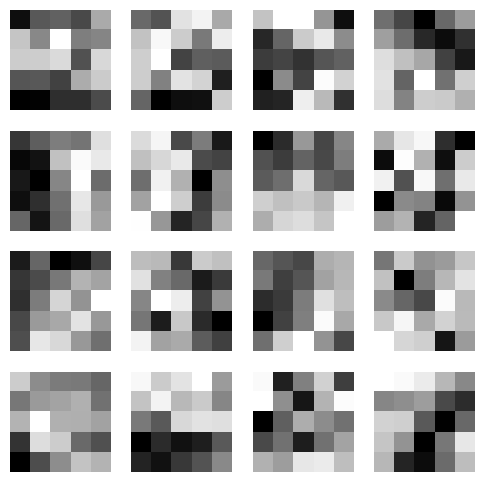

In [36]:
conv_layer = network.conv_layers[0][0].w.detach().squeeze()

fig, axes = plt.subplots(4, 4, figsize=(6, 6))

for i, ax in enumerate(axes.flat):
    ax.imshow(conv_layer[i], cmap='gray', interpolation='nearest')
    ax.axis('off')  # hide axis ticks and labels



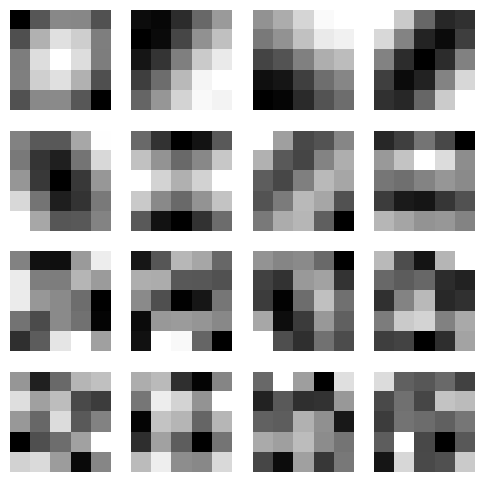

In [37]:
conv_layer = network_hebb.conv_layers[0][0].w.detach().squeeze()

fig, axes = plt.subplots(4, 4, figsize=(6, 6))

for i, ax in enumerate(axes.flat):
    ax.imshow(conv_layer[i], cmap='gray', interpolation='nearest')
    ax.axis('off')  # hide axis ticks and labels

## Pretrain Network Using Hebbian Rule then Train Using BP

In [38]:
pretrained_network = HebbianConvNet(
    in_size = (28, 28),
    in_channels = 1,
    n_filters = [8],
    out_channels = 10,
    conv_options = {
            'kernel_size': (5,5), 
            'stride': 1, 
            'padding': 1, 
            'bias': False, 
            'learning_rate': 1e-4
    },
    conv_act = 'none',
    fc_options = {
        'bias': False, 
        'learning_rate': 1e-4
    },
    fc_act = 'none',
    learning_rule = 'sanger',
)
for epoch in range(5):
    hebbian_train_step(pretrained_network, unsupervised_loader, epoch=epoch)

Train Epoch: 0 [0/10000 (0%)]
Train Epoch: 1 [0/10000 (0%)]
Train Epoch: 2 [0/10000 (0%)]
Train Epoch: 3 [0/10000 (0%)]
Train Epoch: 4 [0/10000 (0%)]


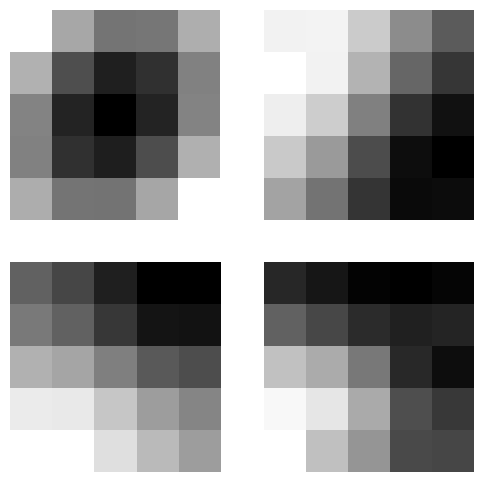

In [39]:
conv_layer = pretrained_network.conv_layers[0][0].w.detach().squeeze()

fig, axes = plt.subplots(2, 2, figsize=(6, 6))

for i, ax in enumerate(axes.flat):
    ax.imshow(conv_layer[i], cmap='gray', interpolation='nearest')
    ax.axis('off')  # hide axis ticks and labels


In [40]:
def fine_tune(model, train_loader, optimizer, epoch, device='cpu'):
    for param in model.parameters():
        param.requires_grad = False

    # Unfreeze everything
    for param in model.fc.parameters():
        param.requires_grad = True

    for batch_idx, (data, target) in enumerate(train_loader):
        optimizer.zero_grad()
        data, target = data.to(device), target.to(device)
        output = model(data)
        loss = F.cross_entropy(output, target)
        loss.backward()
        optimizer.step()

        if batch_idx % 100 == 0:
            print('Train Epoch: {} [{}/{} ({:.0f}%)]\tLoss: {:.6f}'.format(
                epoch, batch_idx * len(data), len(train_loader.dataset),
                100. * batch_idx / len(train_loader), loss.item()))


In [41]:
optimizer = torch.optim.Adam(pretrained_network.parameters(), lr=1e-3)

for epoch in range(5):
    fine_tune(pretrained_network, train_loader, optimizer, epoch=epoch)

test(pretrained_network, test_loader)

Train Epoch: 0 [0/50000 (0%)]	Loss: 2.476643
Train Epoch: 0 [12800/50000 (26%)]	Loss: 0.402531
Train Epoch: 0 [25600/50000 (51%)]	Loss: 0.326190
Train Epoch: 0 [38400/50000 (77%)]	Loss: 0.338331
Train Epoch: 1 [0/50000 (0%)]	Loss: 0.262403
Train Epoch: 1 [12800/50000 (26%)]	Loss: 0.290860
Train Epoch: 1 [25600/50000 (51%)]	Loss: 0.234319
Train Epoch: 1 [38400/50000 (77%)]	Loss: 0.268012
Train Epoch: 2 [0/50000 (0%)]	Loss: 0.170038
Train Epoch: 2 [12800/50000 (26%)]	Loss: 0.154222
Train Epoch: 2 [25600/50000 (51%)]	Loss: 0.249456
Train Epoch: 2 [38400/50000 (77%)]	Loss: 0.119253
Train Epoch: 3 [0/50000 (0%)]	Loss: 0.252586
Train Epoch: 3 [12800/50000 (26%)]	Loss: 0.191776
Train Epoch: 3 [25600/50000 (51%)]	Loss: 0.270569
Train Epoch: 3 [38400/50000 (77%)]	Loss: 0.176216
Train Epoch: 4 [0/50000 (0%)]	Loss: 0.099788
Train Epoch: 4 [12800/50000 (26%)]	Loss: 0.088225
Train Epoch: 4 [25600/50000 (51%)]	Loss: 0.142006
Train Epoch: 4 [38400/50000 (77%)]	Loss: 0.107205

Test set: Average loss: 

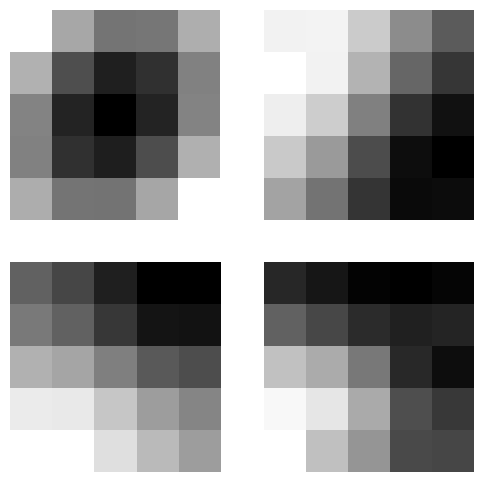

In [42]:
conv_layer = pretrained_network.conv_layers[0][0].w.detach().squeeze().numpy()

fig, axes = plt.subplots(2, 2, figsize=(6, 6))

for i, ax in enumerate(axes.flat):
    ax.imshow(conv_layer[i], cmap='gray', interpolation='nearest')
    ax.axis('off')  # hide axis ticks and labels


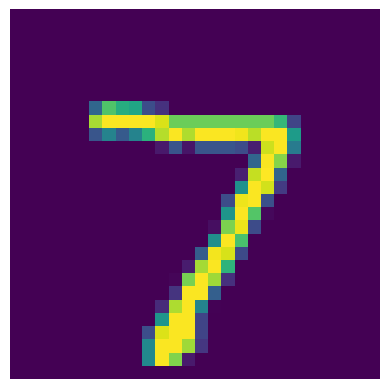

In [43]:
image_tensor, label = pretrain_dataset[0]
image_array = image_tensor.squeeze().numpy()

plt.imshow(image_array)
plt.axis(False);

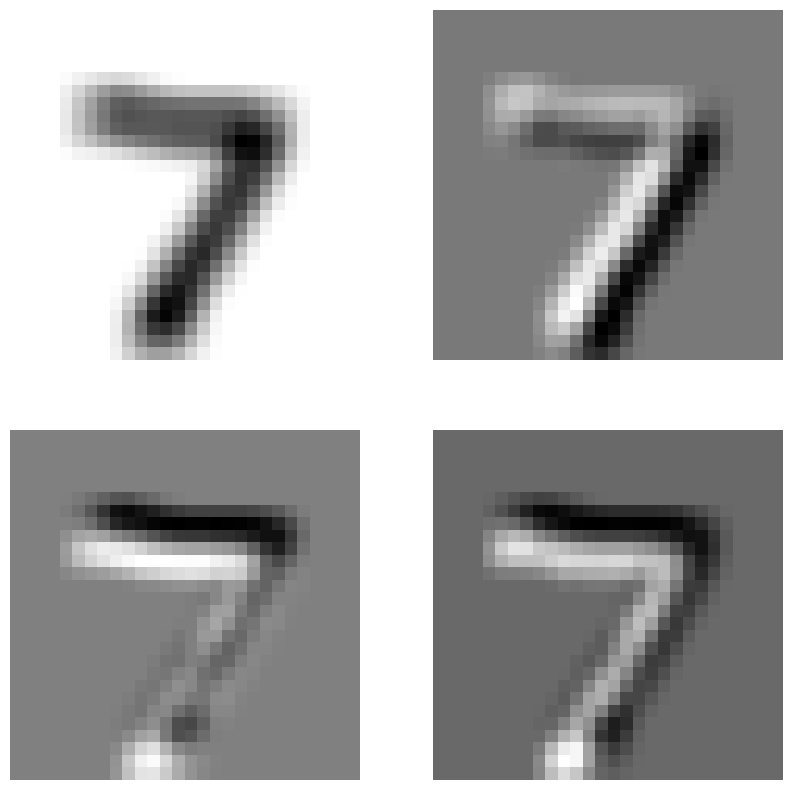

In [44]:
fig, axes = plt.subplots(2, 2, figsize=(10, 10))

for i, ax in enumerate(axes.flat):
    filtered_img = convolve2d(image_array, conv_layer[i], mode='same')
    ax.imshow(filtered_img, cmap='gray', interpolation='nearest')
    ax.axis('off')  # hide axis ticks and labels


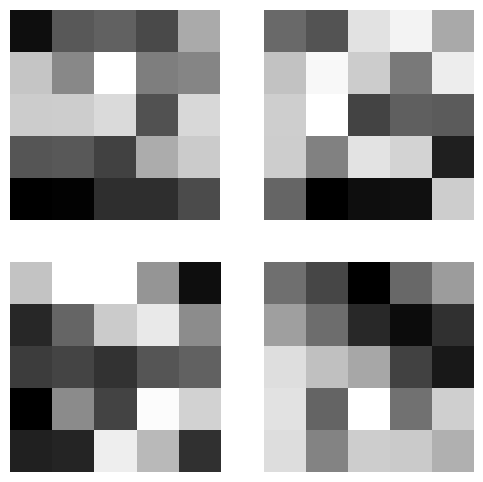

In [45]:
conv_layer = network.conv_layers[0][0].w.detach().squeeze().numpy()

fig, axes = plt.subplots(2, 2, figsize=(6, 6))

for i, ax in enumerate(axes.flat):
    ax.imshow(conv_layer[i], cmap='gray', interpolation='nearest')
    ax.axis('off')  # hide axis ticks and labels


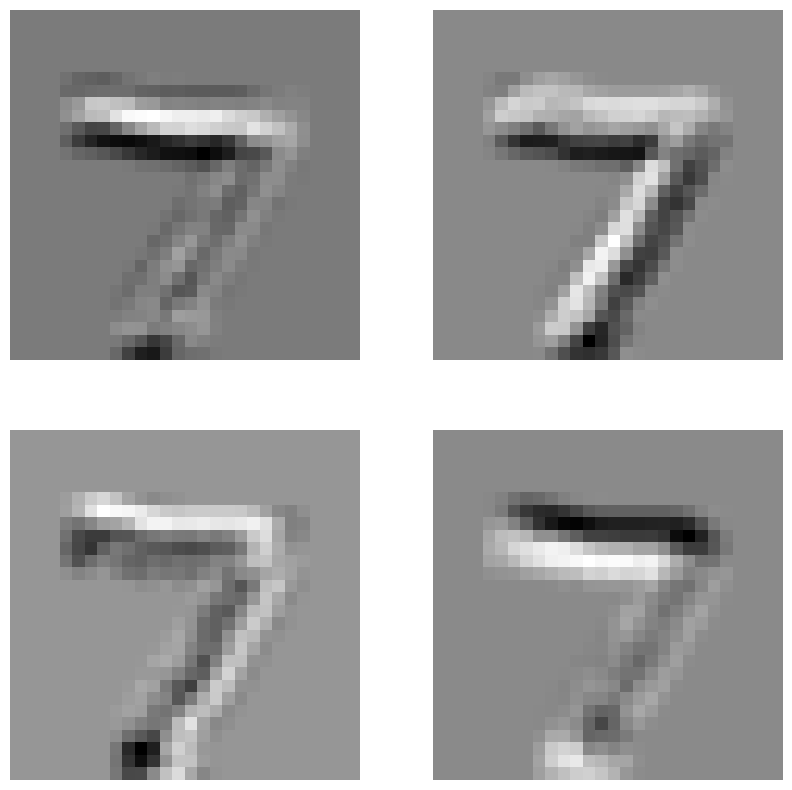

In [46]:
fig, axes = plt.subplots(2, 2, figsize=(10, 10))

for i, ax in enumerate(axes.flat):
    filtered_img = convolve2d(image_array, conv_layer[i], mode='same')
    ax.imshow(filtered_img, cmap='gray', interpolation='nearest')
    ax.axis('off')  # hide axis ticks and labels


In [47]:
from sklearn.decomposition import PCA

In [48]:
data = F.unfold(pretrain_dataset.data.unsqueeze(1).float(), 5, padding=2).transpose(1, 2)
print(data.shape)
data = data.reshape(-1, 25)
print(data.shape)

torch.Size([10000, 784, 25])
torch.Size([7840000, 25])


In [49]:
N, C, H, W = pretrain_dataset.data.unsqueeze(1).shape
C = 8
pca = PCA(C)
pca_out = torch.tensor(pca.fit_transform(data))
pca_out = pca_out.reshape(N,-1, C).transpose(1, 2)
pca_out = pca_out.reshape(N, C, H, W).numpy()

pca_out.shape

(10000, 8, 28, 28)

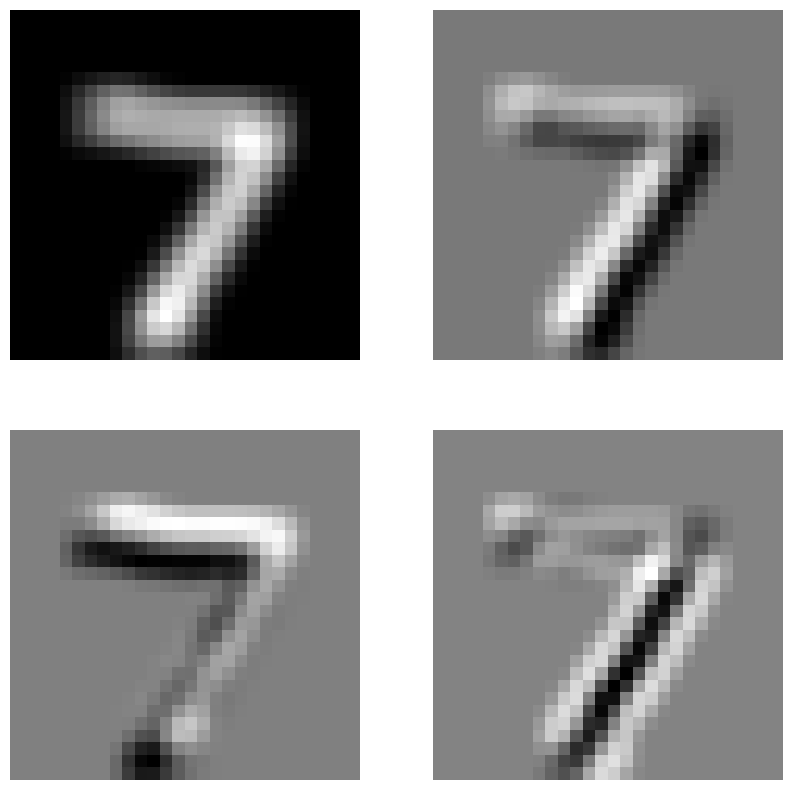

In [50]:
fig, axes = plt.subplots(2, 2, figsize=(10, 10))

for i, ax in enumerate(axes.flat):
    pca_img = pca_out[0][i]
    ax.imshow(pca_img, cmap='gray', interpolation='nearest')
    ax.axis('off')  # hide axis ticks and labels
